# Exploratory Data Analysis & Statistical Insights
**Business context:** A subscription-style retail business wants to understand what drives customer retention, spend and satisfaction, and whether its discount strategy is working.

**Notebook outline**
1. Data loading & quality check
2. Descriptive statistics (mean, median, std, quartiles)
3. Distributions, box plots & anomaly detection
4. Correlation heatmap & multivariate views
5. Hypothesis testing (3 business hypotheses)
6. Top 5 critical findings

> **Note on data:** no dataset was supplied with the task, so this notebook generates a reproducible synthetic customer dataset (`seed=42`, n=5,000) with realistic structure, missing values and outliers. To use real data, replace the cell in Section 1 with `df = pd.read_csv("your_file.csv")` - every later cell works on the same column names.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)

## 1. Data loading & quality check

In [2]:
n = 5000
segment = rng.choice(["Consumer", "Small Business", "Enterprise"], n, p=[0.55, 0.33, 0.12])
region = rng.choice(["North", "South", "East", "West"], n)
age = np.clip(rng.normal(38, 11, n), 18, 80).round()
tenure = np.clip(rng.gamma(2.2, 11, n), 1, 120).round()
discount = np.clip(rng.choice([0, 5, 10, 15, 20, 30, 40], n, p=[.18, .17, .2, .17, .14, .09, .05]) + rng.normal(0, 1.5, n), 0, 50).round(1)
seg_aov = pd.Series(segment).map({"Consumer": 55, "Small Business": 120, "Enterprise": 340}).values
aov = rng.lognormal(np.log(seg_aov), 0.35) * (1 - discount / 150)
orders = np.clip(rng.poisson(6 + tenure / 25 + discount / 12), 1, None)
tickets = rng.poisson(1.2 + 0.015 * (discount > 25) * 10, n)
satisfaction = np.clip(8.2 - 0.55 * tickets + 0.01 * tenure + rng.normal(0, 1.1, n), 1, 10).round(1)
logit = (-0.2 + 0.45 * (satisfaction - 7) + 0.012 * tenure + 0.09 * discount - 0.0032 * discount**2 - 0.1 * tickets)
retained = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
total_spend = (aov * orders).round(2)

df = pd.DataFrame(dict(customer_id=np.arange(1, n + 1), age=age, region=region, segment=segment,
                       tenure_months=tenure, discount_rate=discount, avg_order_value=aov.round(2),
                       orders_per_year=orders, support_tickets=tickets, satisfaction=satisfaction,
                       total_spend=total_spend, retained=retained))
# inject data-quality issues: missing values and a few extreme outliers
df.loc[rng.choice(n, 120, replace=False), "satisfaction"] = np.nan
df.loc[rng.choice(n, 60, replace=False), "age"] = np.nan
df.loc[rng.choice(n, 15, replace=False), "avg_order_value"] *= rng.uniform(6, 12, 15)
df["total_spend"] = (df["avg_order_value"] * df["orders_per_year"]).round(2)
df.head()

,customer_id,age,region,segment,tenure_months,discount_rate,avg_order_value,orders_per_year,support_tickets,satisfaction,total_spend,retained
0,1,38.0,South,Small Business,21.0,0.0,144.69,7,1,NaN,1012.83,1
1,2,25.0,North,Consumer,18.0,0.0,100.18,8,2,7.8,801.44,0
2,3,36.0,East,Small Business,44.0,10.8,96.50,12,1,8.3,1158.00,0
3,4,28.0,East,Small Business,50.0,0.0,47.52,9,3,7.7,427.68,0
4,5,35.0,South,Consumer,32.0,5.9,88.05,12,1,7.7,1056.60,1


In [3]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").join(df.isna().sum().to_frame("missing")).assign(pct_missing=lambda d: (d.missing / len(df) * 100).round(2)))
print("Duplicate customer_ids:", df.customer_id.duplicated().sum())

Shape: (5000, 12)


,dtype,missing,pct_missing
customer_id,int64,0,0.0
age,float64,60,1.2
region,str,0,0.0
segment,str,0,0.0
tenure_months,float64,0,0.0
discount_rate,float64,0,0.0
avg_order_value,float64,0,0.0
orders_per_year,int64,0,0.0
support_tickets,int64,0,0.0
satisfaction,float64,120,2.4


Duplicate customer_ids: 0


In [4]:
# Impute missing numerics with the median (robust to outliers); keep a flag for transparency
for c in ["satisfaction", "age"]:
    df[c + "_was_missing"] = df[c].isna()
    df[c] = df[c].fillna(df[c].median())
num_cols = ["age", "tenure_months", "discount_rate", "avg_order_value", "orders_per_year", "support_tickets", "satisfaction", "total_spend"]

## 2. Descriptive statistics

In [5]:
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["skew"] = df[num_cols].skew()
desc = desc[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skew"]].round(2)
desc

,count,mean,median,std,min,25%,50%,75%,max,skew
age,5000.0,37.84,38.00,10.65,18.00,31.00,38.00,45.00,80.00,0.22
tenure_months,5000.0,24.56,21.00,16.56,1.00,12.00,21.00,33.00,120.00,1.27
discount_rate,5000.0,12.94,10.90,10.54,0.00,4.80,10.90,18.90,45.20,0.90
avg_order_value,5000.0,107.69,71.32,108.42,16.50,47.67,71.32,119.69,2103.83,4.08
orders_per_year,5000.0,8.11,8.00,3.12,1.00,6.00,8.00,10.00,21.00,0.41
support_tickets,5000.0,1.21,1.00,1.09,0.00,0.00,1.00,2.00,6.00,0.84
satisfaction,5000.0,7.74,7.80,1.22,3.10,6.90,7.80,8.60,10.00,-0.25
total_spend,5000.0,872.26,552.42,1062.46,16.65,344.58,552.42,980.38,31557.40,7.77


In [6]:
display(df.groupby("segment")[["avg_order_value", "total_spend", "satisfaction", "retained"]].agg(["mean", "median"]).round(2))
print("Overall retention rate:", round(df.retained.mean() * 100, 1), "%")

avg_order_value         total_spend          satisfaction  \
                          mean  median        mean   median         mean   
segment                                                                    
Consumer                 55.03   50.13      443.86   387.00         7.74   
Enterprise              329.18  308.20     2659.02  2329.20         7.71   
Small Business          119.57  108.85      974.14   845.46         7.73   

                      retained         
               median     mean median  
segment                                
Consumer          7.8     0.62    1.0  
Enterprise        7.8     0.63    1.0  
Small Business    7.8     0.61    1.0

Overall retention rate: 61.7 %


**Reading the table:** a mean well above the median (positive skew) in `avg_order_value` and `total_spend` signals right-skewed spend with a few very large customers. This matters later: it means non-parametric tests and medians are safer than means for spend.

## 3. Distributions, box plots & anomaly detection

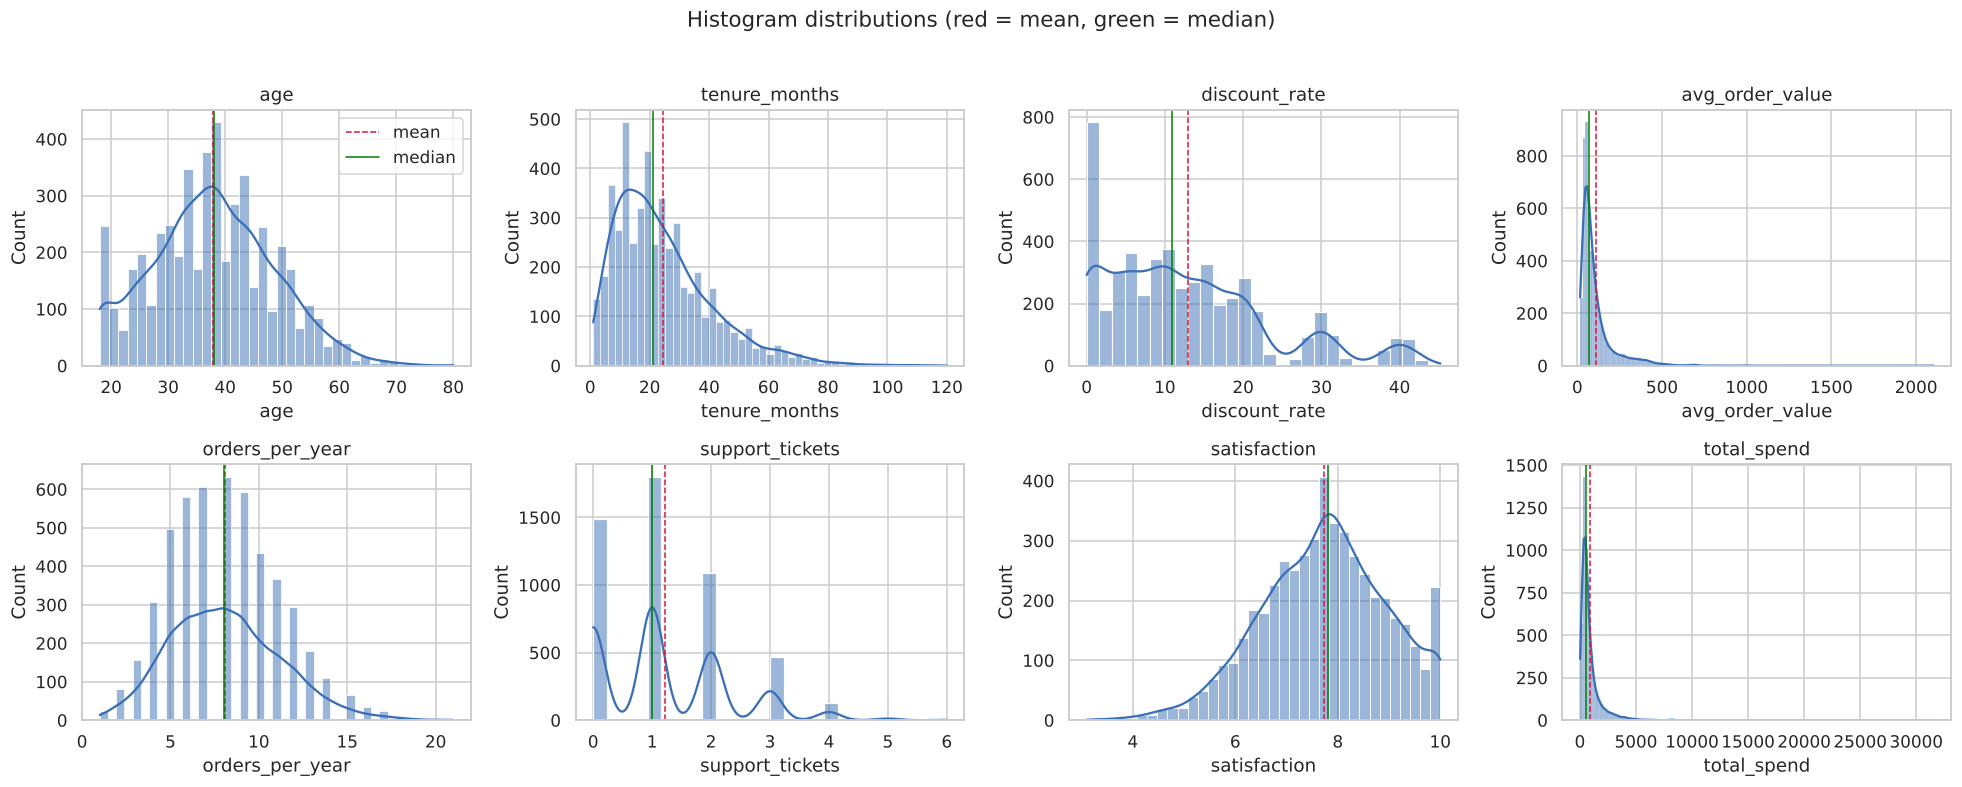

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color="#3b6fb6")
    ax.axvline(df[c].mean(), color="crimson", ls="--", lw=1, label="mean")
    ax.axvline(df[c].median(), color="green", ls="-", lw=1, label="median")
    ax.set_title(c)
axes[0, 0].legend()
plt.suptitle("Histogram distributions (red = mean, green = median)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

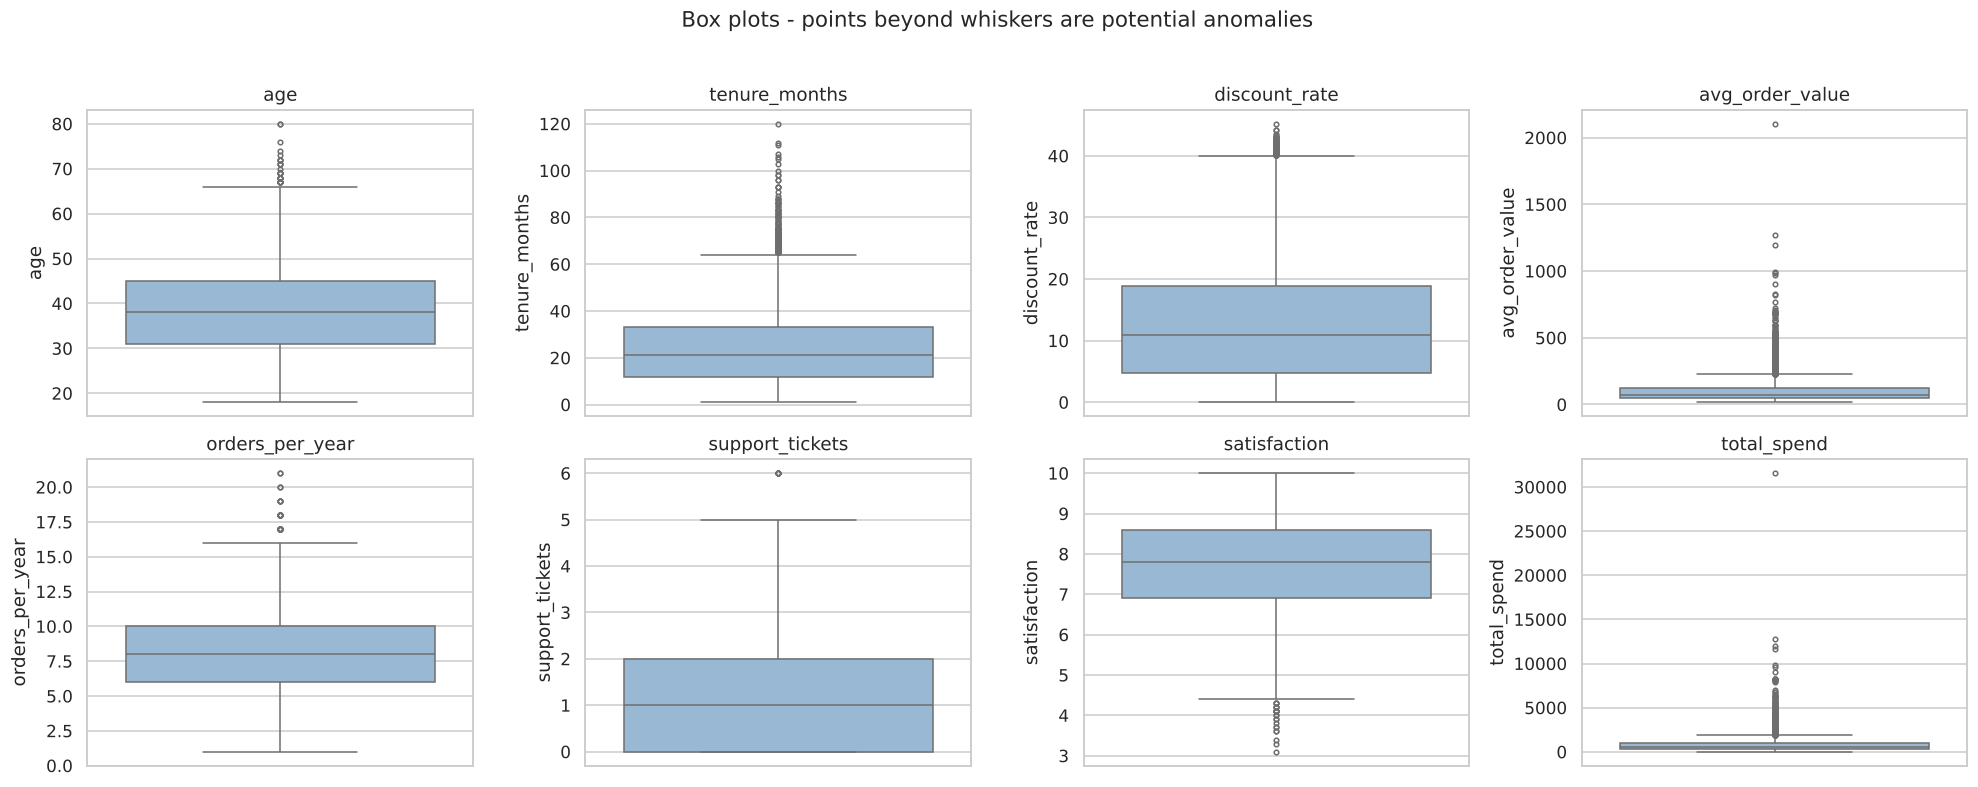

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#8fb8de", fliersize=3)
    ax.set_title(c)
plt.suptitle("Box plots - points beyond whiskers are potential anomalies", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

In [9]:
# IQR rule (1.5 x IQR) and z-score rule for anomaly detection
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = np.abs(stats.zscore(df[c]))
    rows.append((c, int(((df[c] < lo) | (df[c] > hi)).sum()), int((z > 3).sum()), round(lo, 1), round(hi, 1)))
outliers = pd.DataFrame(rows, columns=["variable", "IQR_outliers", "z>3_outliers", "lower_fence", "upper_fence"]).set_index("variable")
outliers

,IQR_outliers,z>3_outliers,lower_fence,upper_fence
variable,,,,
age,28,12,10.0,66.0
tenure_months,152,58,-19.5,64.5
discount_rate,126,1,-16.3,40.0
avg_order_value,504,100,-60.4,227.7
orders_per_year,43,20,0.0,16.0
support_tickets,6,33,-3.0,5.0
satisfaction,24,12,4.4,11.1
total_spend,459,88,-609.1,1934.1


In [10]:
extreme = df.nlargest(10, "avg_order_value")[["customer_id", "segment", "avg_order_value", "orders_per_year", "total_spend"]]
print("Top 10 AOV values - note the extreme anomalies vs. segment norms:")
extreme

Top 10 AOV values - note the extreme anomalies vs. segment norms:


,customer_id,segment,avg_order_value,orders_per_year,total_spend
872,873,Enterprise,2103.826610,15,31557.40
1509,1510,Small Business,1272.260226,10,12722.60
4992,4993,Small Business,1197.583262,10,11975.83
1108,1109,Enterprise,994.970000,5,4974.85
606,607,Small Business,982.948742,8,7863.59
411,412,Small Business,968.132633,12,11617.59
838,839,Consumer,899.776352,7,6298.43
177,178,Enterprise,828.150000,3,2484.45
2151,2152,Consumer,821.942049,10,8219.42
1390,1391,Enterprise,766.370000,1,766.37


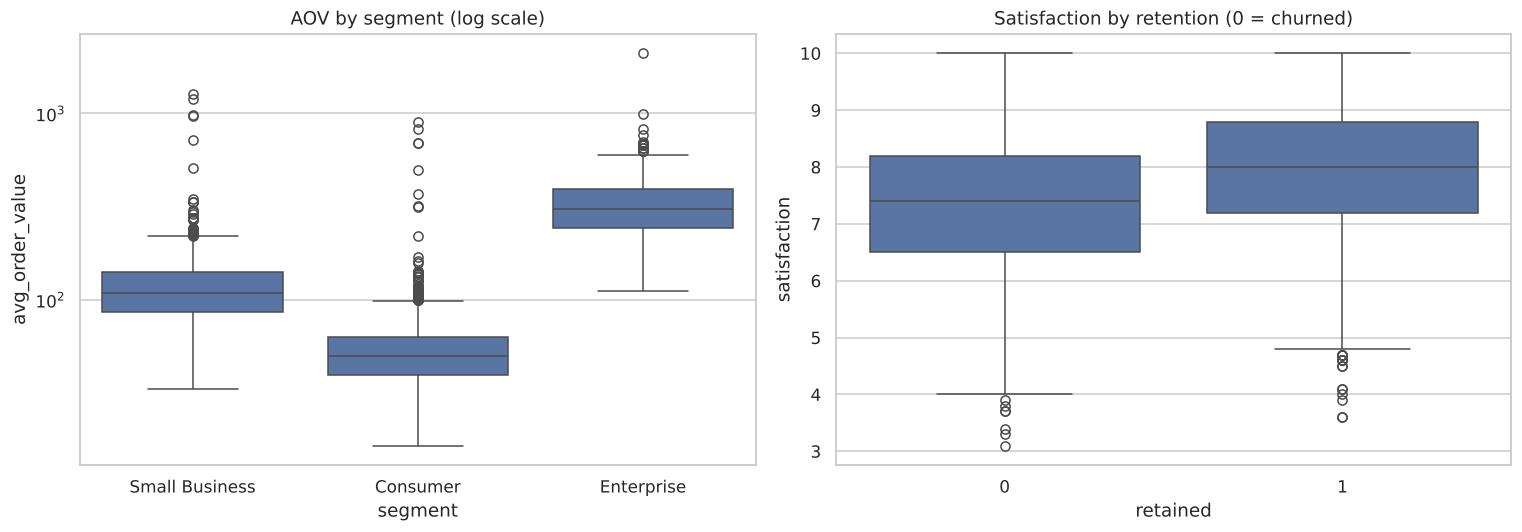

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="segment", y="avg_order_value", ax=axes[0]); axes[0].set_yscale("log"); axes[0].set_title("AOV by segment (log scale)")
sns.boxplot(data=df, x="retained", y="satisfaction", ax=axes[1]); axes[1].set_title("Satisfaction by retention (0 = churned)")
plt.tight_layout(); plt.show()

## 4. Correlation & multivariate analysis

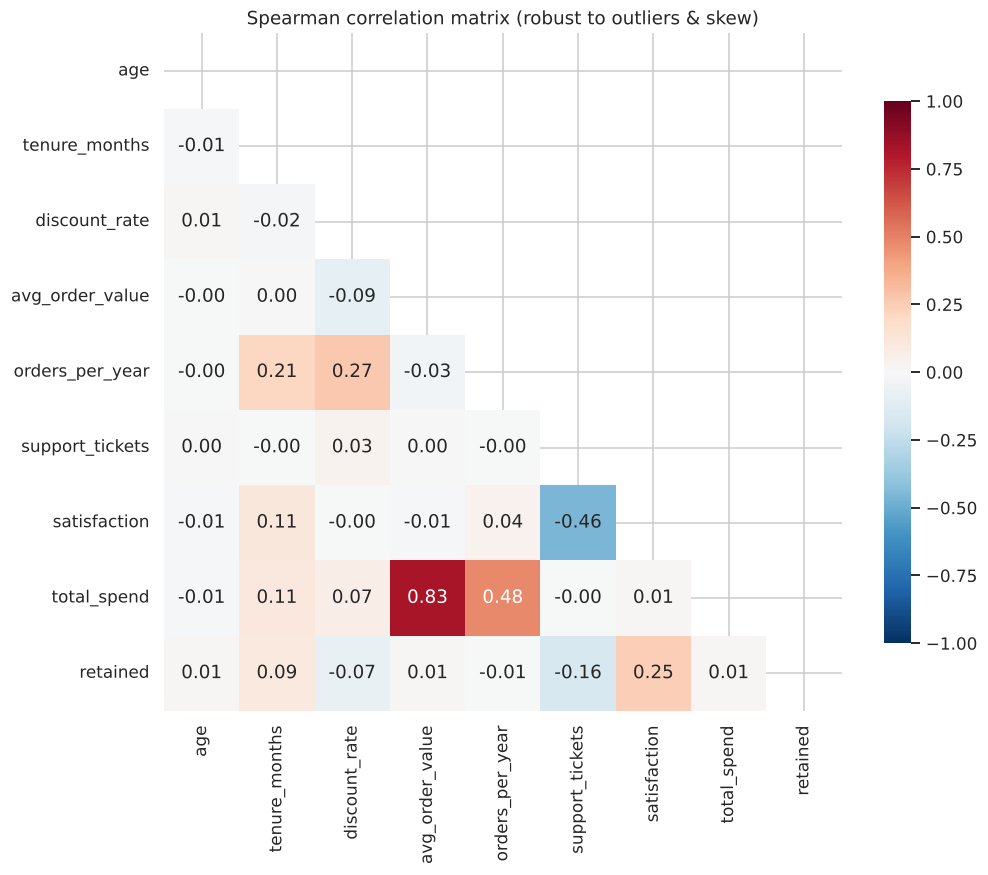

,level_0,level_1,rho
66,total_spend,avg_order_value,0.828
67,total_spend,orders_per_year,0.484
59,satisfaction,support_tickets,-0.455
38,orders_per_year,discount_rate,0.271
78,retained,satisfaction,0.247
37,orders_per_year,tenure_months,0.211
77,retained,support_tickets,-0.165
55,satisfaction,tenure_months,0.113


In [12]:
corr = df[num_cols + ["retained"]].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Spearman correlation matrix (robust to outliers & skew)"); plt.show()
pairs = corr.where(~mask).stack().rename("rho").reset_index()
pairs = pairs[pairs.level_0 != pairs.level_1]
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(8).round(3)

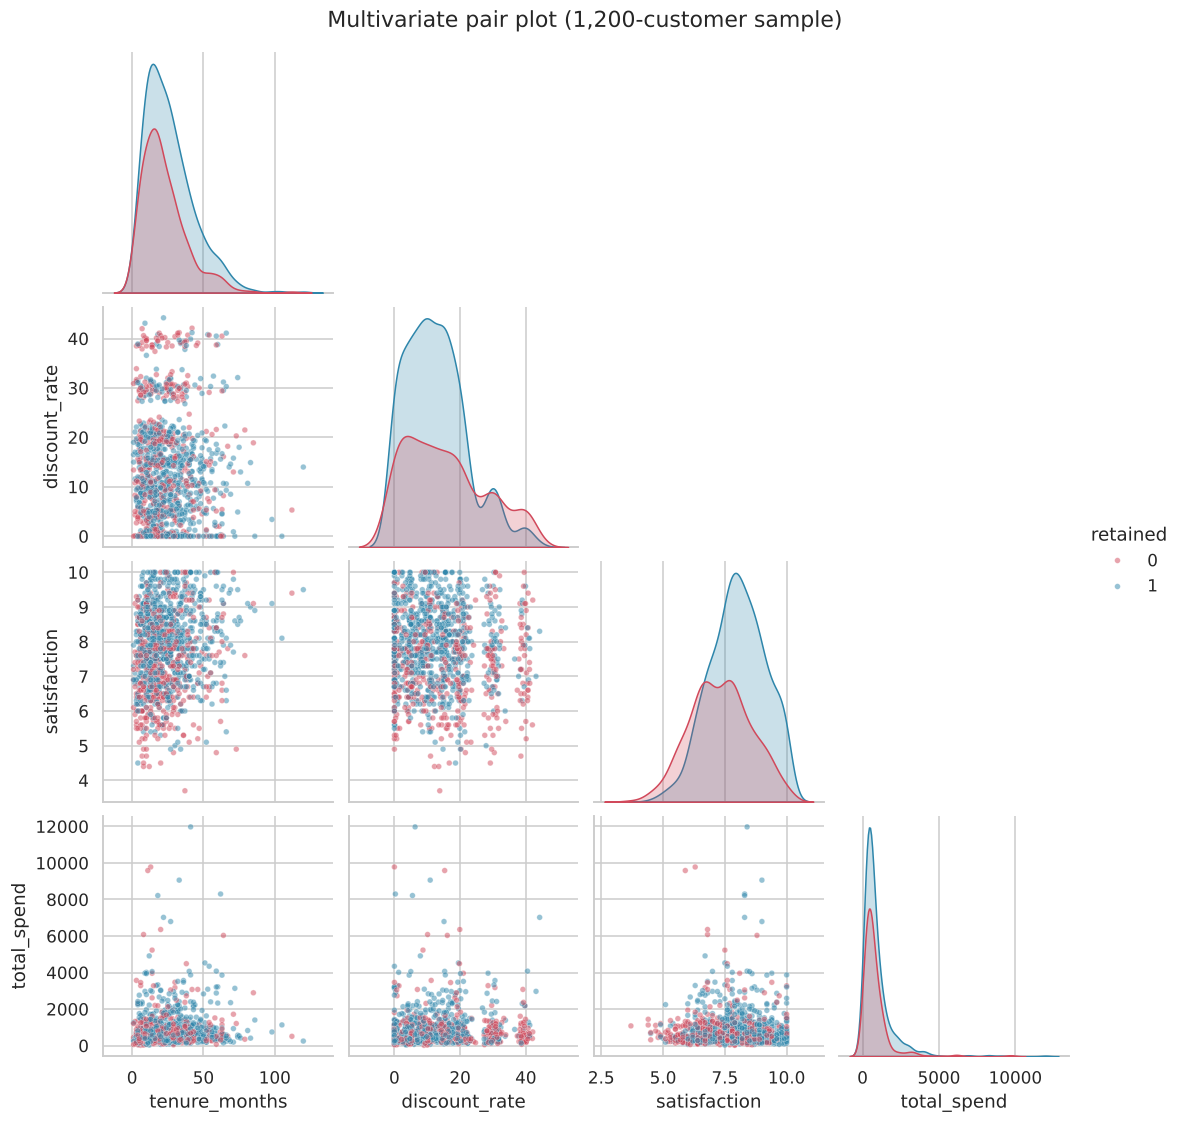

In [13]:
sample = df.sample(1200, random_state=1)
sns.pairplot(sample, vars=["tenure_months", "discount_rate", "satisfaction", "total_spend"], hue="retained",
             palette={0: "#d1495b", 1: "#2e86ab"}, plot_kws=dict(alpha=.5, s=14), corner=True)
plt.suptitle("Multivariate pair plot (1,200-customer sample)", y=1.02); plt.show()

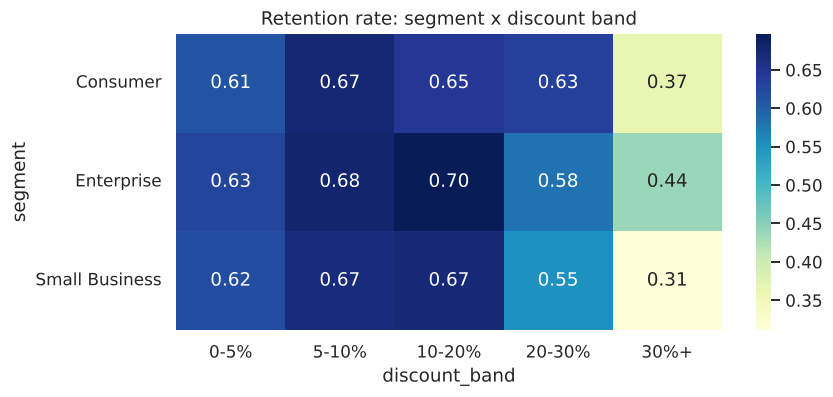

,mean,count
discount_band,,
0-5%,0.616,1327
5-10%,0.672,973
10-20%,0.660,1650
20-30%,0.603,609
30%+,0.361,441


In [14]:
df["discount_band"] = pd.cut(df.discount_rate, [-0.1, 5, 10, 20, 30, 60], labels=["0-5%", "5-10%", "10-20%", "20-30%", "30%+"])
pivot = df.pivot_table(index="segment", columns="discount_band", values="retained", aggfunc="mean").round(3)
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu"); plt.title("Retention rate: segment x discount band"); plt.show()
ret_by_band = df.groupby("discount_band").retained.agg(["mean", "count"]).round(3)
ret_by_band

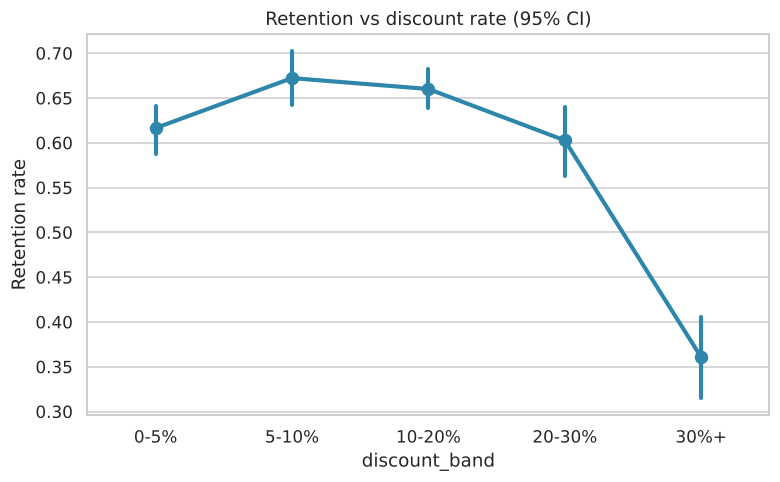

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.pointplot(data=df, x="discount_band", y="retained", errorbar=("ci", 95), ax=ax, color="#2e86ab")
ax.set_ylabel("Retention rate"); ax.set_title("Retention vs discount rate (95% CI)"); plt.show()

## 5. Hypothesis testing
All tests use a significance level of **alpha = 0.05**. Effect sizes are reported alongside p-values because with n = 5,000 even tiny effects are 'significant'.

### H1 - Customer retention depends on the discount rate
- **H0:** retention rate is the same across discount bands.
- **H1:** retention rate differs by discount band (chi-square test of independence), and the relationship is non-linear (modest discounts help; deep discounts do not).

In [16]:
ct = pd.crosstab(df.discount_band, df.retained)
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramer's V = {cramers_v:.3f}")
rho, p_lin = stats.spearmanr(df.discount_rate, df.retained)
print(f"Linear (Spearman) discount vs retained: rho = {rho:.3f}, p = {p_lin:.3g}")
ct.assign(retention_rate=(ct[1] / ct.sum(axis=1)).round(3))

Chi-square = 148.76, dof = 4, p = 3.75e-31, Cramer's V = 0.172
Linear (Spearman) discount vs retained: rho = -0.070, p = 6.38e-07


retained,0,1,retention_rate
discount_band,,,
0-5%,509,818,0.616
5-10%,319,654,0.672
10-20%,561,1089,0.660
20-30%,242,367,0.603
30%+,282,159,0.361


### H2 - Average order value differs across customer segments
- **H0:** AOV distributions are identical across Consumer / Small Business / Enterprise.
- **H1:** at least one segment differs. Because AOV is heavily skewed, we use the Kruskal-Wallis test (and confirm with Welch ANOVA on log values).

In [17]:
groups = [g.avg_order_value.values for _, g in df.groupby("segment")]
H, p_kw = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(df) - len(groups))
print(f"Kruskal-Wallis H = {H:.1f}, p = {p_kw:.2e}, epsilon^2 = {eps2:.3f}")
lg = [np.log(g) for g in groups]
F, p_a = stats.f_oneway(*lg)
print(f"ANOVA on log(AOV): F = {F:.1f}, p = {p_a:.2e}")
df.groupby("segment").avg_order_value.agg(["median", "mean", "count"]).round(1)

Kruskal-Wallis H = 3332.6, p = 0.00e+00, epsilon^2 = 0.667
ANOVA on log(AOV): F = 6363.6, p = 0.00e+00


,median,mean,count
segment,,,
Consumer,50.1,55.0,2794
Enterprise,308.2,329.2,577
Small Business,108.8,119.6,1629


### H3 - Customers with many support tickets are less satisfied
- **H0:** satisfaction is the same for customers with <3 tickets and >=3 tickets.
- **H1:** the high-ticket group has lower satisfaction (one-sided Mann-Whitney U; Cohen's d reported for effect size).

High-ticket n=627, mean satisfaction 6.56 | Low-ticket n=4373, mean 7.90
Mann-Whitney U p = 7.89e-125 | Welch t p = 6.95e-113 | Cohen's d = -1.16


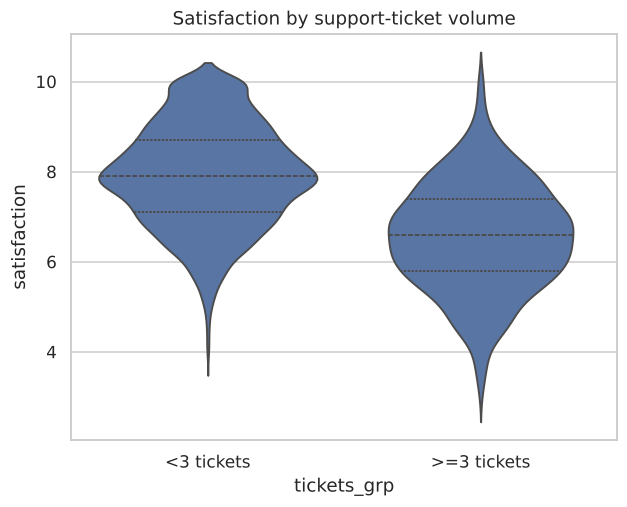

In [18]:
hi = df.loc[df.support_tickets >= 3, "satisfaction"]; lo = df.loc[df.support_tickets < 3, "satisfaction"]
U, p_mw = stats.mannwhitneyu(hi, lo, alternative="less")
t, p_t = stats.ttest_ind(hi, lo, equal_var=False)
d = (hi.mean() - lo.mean()) / np.sqrt((hi.var() + lo.var()) / 2)
print(f"High-ticket n={len(hi)}, mean satisfaction {hi.mean():.2f} | Low-ticket n={len(lo)}, mean {lo.mean():.2f}")
print(f"Mann-Whitney U p = {p_mw:.2e} | Welch t p = {p_t:.2e} | Cohen's d = {d:.2f}")
sns.violinplot(data=df.assign(tickets_grp=np.where(df.support_tickets >= 3, ">=3 tickets", "<3 tickets")), x="tickets_grp", y="satisfaction", inner="quartile")
plt.title("Satisfaction by support-ticket volume"); plt.show()

In [19]:
# Supporting check: which variables independently predict retention? (standardised logistic regression)
import statsmodels.api as sm
X = df[["satisfaction", "tenure_months", "discount_rate", "support_tickets"]].copy()
X["discount_sq"] = X.discount_rate ** 2
Xs = (X - X.mean()) / X.std()
res = sm.Logit(df.retained, sm.add_constant(Xs)).fit(disp=0)
pd.DataFrame({"std_coef": res.params, "odds_ratio": np.exp(res.params), "p_value": res.pvalues}).round(4)

,std_coef,odds_ratio,p_value
const,0.5193,1.6809,0.0000
satisfaction,0.4903,1.6328,0.0000
tenure_months,0.1765,1.1931,0.0000
discount_rate,0.6480,1.9117,0.0000
support_tickets,-0.1043,0.9010,0.0027
discount_sq,-0.9627,0.3819,0.0000


## 6. Top 5 critical findings

**1. Deep discounts (30%+) hurt retention instead of helping it.**
Retention is 61.6% at 0-5% discount, peaks at 67.2% for 5-10% and 66.0% for 10-20%, then falls to 60.3% at 20-30% and just **36.1% at 30%+** (n = 441). The chi-square test is highly significant (chi2 = 148.8, p < 1e-30, Cramer's V = 0.17), while the *linear* correlation is almost zero (rho = -0.07), so a straight-line view hides the effect. The logistic model confirms the shape: a positive discount term (OR 1.91) and a strong negative squared term (OR 0.38). **Action:** cap standard discounts around 10-20% and audit the 30%+ cohort.

**2. Satisfaction is the strongest controllable driver of retention, and support tickets erode it.**
Customers with 3+ tickets score **6.56 vs 7.90** satisfaction (Mann-Whitney p < 1e-120, Cohen's d = -1.16, a very large effect). Satisfaction correlates with tickets at rho = -0.46 and with retention at rho = +0.25; each standard deviation of satisfaction raises retention odds by about 63% (OR 1.63). **Action:** treat 3+ tickets as an early-warning churn flag.

**3. Spend is extremely right-skewed, so means are misleading.**
Mean AOV is $107.7 vs a median of $71.3 (skew 4.1); total spend has a mean of $872 vs a median of $552 (skew 7.8). 504 customers fall outside the IQR fences on AOV, and the largest single customer has AOV $2,104. Segments differ strongly (Kruskal-Wallis H = 3,333, p ~ 0, epsilon^2 = 0.67): median AOV is **$50 Consumer, $109 Small Business, $308 Enterprise**. **Action:** report medians by segment, and review the ~15 extreme-AOV records for data-entry errors vs genuine whale accounts before using them in forecasts.

**4. Order value drives revenue more than order frequency, and retention does not vary by segment.**
Total spend tracks AOV (rho = 0.83) much more than orders per year (rho = 0.48). Yet retention is nearly identical across segments (Consumer 62%, Enterprise 63%, Small Business 61%), so segment is not a churn lever: the high-value Enterprise segment is no safer than Consumer. **Action:** grow revenue through basket size and upsell, and monitor Enterprise churn closely because each loss costs ~6x a Consumer customer.

**5. Tenure builds loyalty, and data quality needs attention.**
Longer-tenured customers retain better (OR 1.19 per SD, p < 0.001) and order more often (rho = 0.21 with orders/year). Separately, 2.4% of satisfaction scores and 1.2% of ages were missing (median-imputed and flagged), and tenure is skewed (1.27) with 152 IQR outliers, i.e. a long tail of very loyal accounts. **Action:** invest in onboarding in the first 12 months (the 25th percentile of tenure), and fix survey coverage so satisfaction is not missing.

### Hypothesis scorecard
| # | Hypothesis | Test | Result |
|---|-----------|------|--------|
| H1 | Retention depends on discount rate | Chi-square, V = 0.17 | **Reject H0** (p = 3.8e-31); effect is non-linear |
| H2 | AOV differs by segment | Kruskal-Wallis, eps^2 = 0.67 | **Reject H0** (p ~ 0) |
| H3 | 3+ tickets lowers satisfaction | Mann-Whitney, d = -1.16 | **Reject H0** (p = 7.9e-125) |

### Limitations
- The data is **synthetic** (seeded, n = 5,000), so these findings demonstrate the method and are not claims about a real business. Swap in a real CSV in Section 1 to reproduce the analysis.
- All results are associational; discounts and retention are correlated here, not causally identified (a randomized discount test would be the next step).
